# Identitas Diri
Nama : Muhammad Rayhan Zamzami

NIM : 244107020027

Kelas : TI - 3G

Absen : 19

Kelompok PBL: 4

In [ ]:
# import library & setting
import os
import time
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from sklearn.cluster import DBSCAN  # hanya untuk validasi implementasi manual
from sklearn.metrics import (
    silhouette_score,
    davies_bouldin_score,
    calinski_harabasz_score,
    pairwise_distances,
    adjusted_rand_score
)

warnings.filterwarnings('ignore')
plt.style.use('seaborn-v0_8-whitegrid' if 'seaborn-v0_8-whitegrid' in plt.style.available else 'default')
plt.rcParams['font.sans-serif'] = 'DejaVu Sans'
plt.rcParams['figure.dpi'] = 120

from google.colab import drive
drive.mount('/content/drive')
OUTPUT_DIR = "/content/drive/MyDrive/ml-semester5/UTS/outputDBSCAN"
os.makedirs(OUTPUT_DIR, exist_ok=True)

METRIC = 'manhattan'
N_SAMPLE = None
SIL_SAMPLE = 10000
N_VALIDASI = 10000       # ukuran subset untuk membuktikan hasil manual = sklearn
PLOT_N = 30000           # jumlah titik yang digambar di grafik PCA (agar ringan)
CHUNK_SIZE = 400
RANDOM_STATE = 42
np.random.seed(RANDOM_STATE)


def _log(msg):
    print(f"[{time.strftime('%H:%M:%S')}] {msg}", flush=True)


print("[INFO] Library berhasil diimpor.")
print(f"[INFO] Metrik: {METRIC} | N_SAMPLE: {N_SAMPLE} | Random state: {RANDOM_STATE}")

Mounted at /content/drive
[INFO] Library berhasil diimpor.
[INFO] Metrik: manhattan | N_SAMPLE: None | Random state: 42


In [ ]:
# Load Dataset
df_raw = pd.read_csv('/content/drive/MyDrive/ml-semester5/UTS/dataset/diabetes_binary_5050split_health_indicators_BRFSS2015.csv')
print(f"Data awal: {df_raw.shape[0]} baris x {df_raw.shape[1]} kolom")
df_raw.head()

Data awal: 70692 baris x 22 kolom


,Diabetes_binary,HighBP,HighChol,CholCheck,BMI,Smoker,Stroke,HeartDiseaseorAttack,PhysActivity,Fruits,...,AnyHealthcare,NoDocbcCost,GenHlth,MentHlth,PhysHlth,DiffWalk,Sex,Age,Education,Income
0,0.0,1.0,0.0,1.0,26.0,0.0,0.0,0.0,1.0,0.0,...,1.0,0.0,3.0,5.0,30.0,0.0,1.0,4.0,6.0,8.0
1,0.0,1.0,1.0,1.0,26.0,1.0,1.0,0.0,0.0,1.0,...,1.0,0.0,3.0,0.0,0.0,0.0,1.0,12.0,6.0,8.0
2,0.0,0.0,0.0,1.0,26.0,0.0,0.0,0.0,1.0,1.0,...,1.0,0.0,1.0,0.0,10.0,0.0,1.0,13.0,6.0,8.0
3,0.0,1.0,1.0,1.0,28.0,1.0,0.0,0.0,1.0,1.0,...,1.0,0.0,3.0,0.0,3.0,0.0,1.0,11.0,6.0,8.0
4,0.0,0.0,0.0,1.0,29.0,1.0,0.0,0.0,1.0,1.0,...,1.0,0.0,2.0,0.0,0.0,0.0,0.0,8.0,5.0,8.0


In [ ]:
# Cek data awal
print("Tipe data tiap kolom:")
print(df_raw.dtypes.value_counts())

print("\nTotal missing value per kolom (hanya yang > 0):")
missing = df_raw.isnull().sum()
print(missing[missing > 0] if missing.sum() > 0 else "Tidak ada missing value")

print(f"\nJumlah baris duplikat: {df_raw.duplicated().sum()}")

print("\nSebaran kelas Diabetes_binary (0=tidak, 1=diabetes):")
print(df_raw['Diabetes_binary'].value_counts().sort_index())

Tipe data tiap kolom:
float64    22
Name: count, dtype: int64

Total missing value per kolom (hanya yang > 0):
Tidak ada missing value

Jumlah baris duplikat: 1635

Sebaran kelas Diabetes_binary (0=tidak, 1=diabetes):
Diabetes_binary
0.0    35346
1.0    35346
Name: count, dtype: int64


In [ ]:
# preprocessing + pemilihan data
LABEL = 'Diabetes_binary'          # label sudah 0 dan 1
FITUR_DIBUANG = ['Income','CholCheck', 'HvyAlcoholConsump', 'AnyHealthcare', 'NoDocbcCost', 'Education']

df = df_raw.copy()
print(f"Data awal: {len(df)} baris x {df.shape[1]} kolom")

df = df.drop(columns=FITUR_DIBUANG)
print(f"Setelah buang fitur       : {df.shape[1]} kolom (termasuk label)")

n_sebelum_dup = len(df)
df = df.drop_duplicates().reset_index(drop=True)
print(f"Setelah hapus duplikat    : {len(df)} baris (terbuang {n_sebelum_dup - len(df)})")
print(f"Sebaran kelas akhir       : {df[LABEL].value_counts().sort_index().to_dict()}")

y_label = df[LABEL].copy()   # label hanya untuk pembanding, tidak dipakai klastering
df_features = df.drop(columns=[LABEL]).astype(float)
print(f"Jumlah fitur untuk klastering: {df_features.shape[1]}")
print(f"Daftar fitur: {list(df_features.columns)}")

scaler = StandardScaler()
X_all = scaler.fit_transform(df_features.values)
print(f"Bentuk data siap klaster: {X_all.shape}")
print(f"Cek mean 0 dan std 1: {X_all.mean():.4f} / {X_all.std():.4f}")

# Pemilihan data: N_SAMPLE = None -> semua data; angka -> sampel acak sebesar itu
if N_SAMPLE is None or N_SAMPLE >= len(X_all):
    idx_sample = np.arange(len(X_all))
else:
    rng = np.random.RandomState(RANDOM_STATE)
    idx_sample = np.sort(rng.choice(len(X_all), size=N_SAMPLE, replace=False))
X_sample = X_all[idx_sample]
y_sample = y_label.iloc[idx_sample].reset_index(drop=True)
df_sample = df_features.iloc[idx_sample].reset_index(drop=True)
print(f"[DATA] Data klastering: {X_sample.shape[0]} baris x {X_sample.shape[1]} kolom"
      f" ({'seluruh data' if len(idx_sample) == len(X_all) else 'sampel acak'})")
print(f"[DATA] Sebaran label (pembanding): {y_sample.value_counts().sort_index().to_dict()}")
df_sample.head()

Data awal: 70692 baris x 22 kolom
Setelah buang fitur       : 16 kolom (termasuk label)
Setelah hapus duplikat    : 63197 baris (terbuang 7495)
Sebaran kelas akhir       : {0.0: 29885, 1.0: 33312}
Jumlah fitur untuk klastering: 15
Daftar fitur: ['HighBP', 'HighChol', 'BMI', 'Smoker', 'Stroke', 'HeartDiseaseorAttack', 'PhysActivity', 'Fruits', 'Veggies', 'GenHlth', 'MentHlth', 'PhysHlth', 'DiffWalk', 'Sex', 'Age']
Bentuk data siap klaster: (63197, 15)
Cek mean 0 dan std 1: 0.0000 / 1.0000
[DATA] Data klastering: 63197 baris x 15 kolom (seluruh data)
[DATA] Sebaran label (pembanding): {0.0: 29885, 1.0: 33312}


,HighBP,HighChol,BMI,Smoker,Stroke,HeartDiseaseorAttack,PhysActivity,Fruits,Veggies,GenHlth,MentHlth,PhysHlth,DiffWalk,Sex,Age
0,1.0,0.0,26.0,0.0,0.0,0.0,1.0,0.0,1.0,3.0,5.0,30.0,0.0,1.0,4.0
1,1.0,1.0,26.0,1.0,1.0,0.0,0.0,1.0,0.0,3.0,0.0,0.0,0.0,1.0,12.0
2,0.0,0.0,26.0,0.0,0.0,0.0,1.0,1.0,1.0,1.0,0.0,10.0,0.0,1.0,13.0
3,1.0,1.0,28.0,1.0,0.0,0.0,1.0,1.0,1.0,3.0,0.0,3.0,0.0,1.0,11.0
4,0.0,0.0,29.0,1.0,0.0,0.0,1.0,1.0,1.0,2.0,0.0,0.0,0.0,0.0,8.0


In [ ]:
# fungsi jarak hemat memori (dipakai k-distance, hitung tetangga, dan DBSCAN)
# Prinsip: jarak dihitung per potongan baris (CHUNK_SIZE x n) lalu langsung dibuang,
# jadi memori yang dipakai O(CHUNK_SIZE x n), bukan O(n x n).

def _blok_jarak(A, B, metric, B_sq=None):
    """Matriks jarak A x B (float64). Euclidean dikembalikan sebagai jarak KUADRAT (tanpa sqrt, lebih cepat)."""
    if metric == 'euclidean':
        d = A @ B.T
        d *= -2.0
        d += (A * A).sum(axis=1)[:, None]
        d += (B_sq if B_sq is not None else (B * B).sum(axis=1))[None, :]
        np.maximum(d, 0.0, out=d)
        return d
    if metric == 'cosine':          # data sudah L2-normalized -> jarak cosine = 1 - dot product
        d = A @ B.T
        np.subtract(1.0, d, out=d)
        return d
    return pairwise_distances(A, B, metric='manhattan', n_jobs=-1)


def _ambang(eps, metric):
    return eps * eps if metric == 'euclidean' else eps


def kdistance(X, metric, k, chunk_size=CHUNK_SIZE, verbose=False):
    """Jarak ke tetangga ke-k (titik itu sendiri dihitung sebagai tetangga ke-1)."""
    n = len(X)
    out = np.empty(n)
    B_sq = (X * X).sum(axis=1) if metric == 'euclidean' else None
    n_chunk = (n + chunk_size - 1) // chunk_size
    for ci, s in enumerate(range(0, n, chunk_size)):
        d = _blok_jarak(X[s:s + chunk_size], X, metric, B_sq)
        out[s:s + chunk_size] = np.partition(d, k - 1, axis=1)[:, k - 1]
        if verbose and (ci % max(1, n_chunk // 10) == 0):
            _log(f"  k-distance: potongan {ci + 1}/{n_chunk}")
    return np.sqrt(out) if metric == 'euclidean' else out


def hitung_tetangga(X, metric, eps_list, chunk_size=CHUNK_SIZE, verbose=False):
    """Jumlah tetangga (termasuk diri sendiri) untuk SEMUA nilai eps sekaligus, cukup satu kali lewat data."""
    n = len(X)
    thr = [_ambang(e, metric) for e in eps_list]
    counts = np.zeros((len(eps_list), n), dtype=np.int32)
    B_sq = (X * X).sum(axis=1) if metric == 'euclidean' else None
    n_chunk = (n + chunk_size - 1) // chunk_size
    for ci, s in enumerate(range(0, n, chunk_size)):
        d = _blok_jarak(X[s:s + chunk_size], X, metric, B_sq)
        for i, t in enumerate(thr):
            counts[i, s:s + chunk_size] = (d <= t).sum(axis=1)
        if verbose and (ci % max(1, n_chunk // 10) == 0):
            _log(f"  hitung tetangga: potongan {ci + 1}/{n_chunk}")
    return counts


def silhouette_aman(Xm, lab):
    """Silhouette pada sampel acak (SIL_SAMPLE) dari titik non-noise; NaN kalau sampel hanya berisi 1 klaster."""
    try:
        return float(silhouette_score(Xm, lab, metric=METRIC,
                                      sample_size=min(SIL_SAMPLE, len(lab)), random_state=RANDOM_STATE))
    except ValueError:
        return np.nan


print("[INFO] Fungsi jarak hemat memori siap.")

[INFO] Fungsi jarak hemat memori siap.


[PARAM] MinPts = 30
[09:48:01] Menghitung k-distance (satu kali lewat seluruh data, bisa beberapa menit)...
[09:48:03]   k-distance: potongan 1/158
[09:48:18]   k-distance: potongan 16/158
[09:48:33]   k-distance: potongan 31/158
[09:48:48]   k-distance: potongan 46/158
[09:49:03]   k-distance: potongan 61/158
[09:49:19]   k-distance: potongan 76/158
[09:49:35]   k-distance: potongan 91/158
[09:49:50]   k-distance: potongan 106/158
[09:50:05]   k-distance: potongan 121/158
[09:50:20]   k-distance: potongan 136/158
[09:50:35]   k-distance: potongan 151/158
[09:50:42] k-distance selesai.
[K-DIST] Saran eps dari siku kurva: 4.6639
[K-DIST] Persentil ke-50: 2.1799
[K-DIST] Persentil ke-75: 3.4017
[K-DIST] Persentil ke-90: 4.5073
[K-DIST] Persentil ke-95: 5.1785
[K-DIST] Persentil ke-99: 6.5940
[SIMPAN] Grafik k-distance disimpan ke: '/content/drive/MyDrive/ml-sem5/uts/outputDBSCAN/kdistance_manhattan.png'


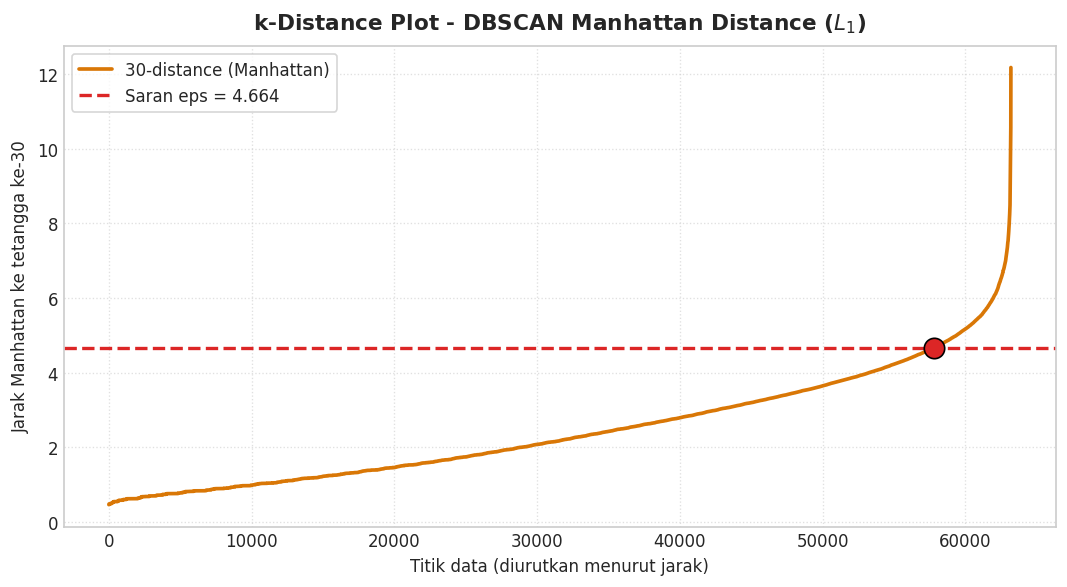

In [ ]:
# k-distance plot untuk menentukan eps (pengganti Elbow Method)
MIN_PTS = 2 * X_sample.shape[1]   # heuristik: 2 x jumlah fitur
print(f"[PARAM] MinPts = {MIN_PTS}")

_log("Menghitung k-distance (satu kali lewat seluruh data, bisa beberapa menit)...")
k_dist = np.sort(kdistance(X_sample, METRIC, MIN_PTS, verbose=len(X_sample) > 50000))
_log("k-distance selesai.")

def find_knee_point(y_vals):
    x = np.arange(len(y_vals), dtype=float)
    xn = (x - x.min()) / (x.max() - x.min())
    yn = (y_vals - y_vals.min()) / (y_vals.max() - y_vals.min())
    p1 = np.array([xn[0], yn[0]])
    line_unit = np.array([xn[-1], yn[-1]]) - p1
    line_unit = line_unit / np.linalg.norm(line_unit)
    pts = np.column_stack([xn, yn]) - p1
    proj = np.outer(pts @ line_unit, line_unit)
    return int(np.argmax(np.linalg.norm(pts - proj, axis=1)))

knee_idx = find_knee_point(k_dist)
eps_suggest = float(k_dist[knee_idx])
print(f"[K-DIST] Saran eps dari siku kurva: {eps_suggest:.4f}")
for q in [50, 75, 90, 95, 99]:
    print(f"[K-DIST] Persentil ke-{q}: {np.percentile(k_dist, q):.4f}")

plt.figure(figsize=(9, 5))
plt.plot(k_dist, linewidth=2.2, color='#D97706', label=f'{MIN_PTS}-distance (Manhattan)')
plt.axhline(eps_suggest, color='#DC2626', linestyle='--', linewidth=2, label=f'Saran eps = {eps_suggest:.3f}')
plt.scatter([knee_idx], [eps_suggest], color='#DC2626', s=150, zorder=5, edgecolor='black')
plt.title('k-Distance Plot - DBSCAN Manhattan Distance ($L_1$)', fontsize=13, fontweight='bold', pad=10)
plt.xlabel('Titik data (diurutkan menurut jarak)')
plt.ylabel(f'Jarak Manhattan ke tetangga ke-{MIN_PTS}')
plt.grid(True, linestyle=':', alpha=0.6)
plt.legend(frameon=True, facecolor='white')
plt.tight_layout()

kdist_path = os.path.join(OUTPUT_DIR, "kdistance_manhattan.png")
plt.savefig(kdist_path, dpi=300)
print(f"[SIMPAN] Grafik k-distance disimpan ke: '{kdist_path}'")
plt.show()

In [ ]:
# class DBSCAN Manhattan (implementasi manual, hemat memori)
class DBSCANManhattan:
    """
    Sama seperti versi sebelumnya (definisi DBSCAN asli), bedanya daftar tetangga TIDAK disimpan.
      1) Titik core ditentukan dengan menghitung jumlah tetangga per potongan baris.
      2) Klaster diperluas per 'gelombang': tetangga dari sekumpulan titik core dicari langsung dengan
         menghitung jarak ke titik yang belum punya klaster saja (makin lama makin sedikit).
    N_eps(p) = { q | ||p - q||_1 <= eps }, termasuk p sendiri. Memori O(n), bukan O(n^2).
    """
    def __init__(self, eps=0.5, min_pts=5, chunk_size=CHUNK_SIZE):
        self.eps = eps
        self.min_pts = min_pts
        self.chunk_size = chunk_size
        self.metric = METRIC
        self.labels_ = None
        self.core_sample_mask_ = None
        self.n_clusters_ = 0
        self.n_noise_ = 0
        self.execution_time_ = 0.0

    def fit(self, X, counts=None, verbose=False):
        start = time.perf_counter()
        n = X.shape[0]
        if counts is None:   # kalau sudah dihitung di luar (dipakai saat uji banyak eps), tidak dihitung ulang
            if verbose:
                _log("  tahap 1/2: hitung jumlah tetangga tiap titik")
            counts = hitung_tetangga(X, self.metric, [self.eps], self.chunk_size, verbose=verbose)[0]
        is_core = counts >= self.min_pts

        if verbose:
            _log(f"  tahap 2/2: perluas klaster ({int(is_core.sum())} titik core)")
        thr = _ambang(self.eps, self.metric)
        labels = np.full(n, -1, dtype=np.int32)   # -1 = noise / belum punya klaster
        cluster_id = 0
        for p in np.where(is_core)[0]:
            if labels[p] != -1:
                continue
            labels[p] = cluster_id
            frontier = np.array([p])
            while len(frontier) > 0:
                cand = np.where(labels == -1)[0]          # hanya titik yang belum punya klaster
                if len(cand) == 0:
                    break
                Xc = X[cand]
                Bc_sq = (Xc * Xc).sum(axis=1) if self.metric == 'euclidean' else None
                hit = np.zeros(len(cand), dtype=bool)
                for s in range(0, len(frontier), self.chunk_size):
                    f = frontier[s:s + self.chunk_size]
                    d = _blok_jarak(X[f], Xc, self.metric, Bc_sq)
                    hit |= (d <= thr).any(axis=0)
                baru = cand[hit]
                labels[baru] = cluster_id                  # core maupun border masuk klaster ini
                frontier = baru[is_core[baru]]             # hanya core baru yang ikut memperluas
            cluster_id += 1

        self.labels_ = labels.astype(int)
        self.core_sample_mask_ = is_core
        self.n_clusters_ = cluster_id
        self.n_noise_ = int(np.sum(labels == -1))
        self.execution_time_ = float(time.perf_counter() - start)
        return self

print("[INFO] Kelas DBSCANManhattan berhasil diinisialisasi.")

[INFO] Kelas DBSCANManhattan berhasil diinisialisasi.


In [ ]:
# uji validasi terhadap DBSCAN sklearn (pada subset, karena sklearn menyimpan daftar tetangga)
rng_v = np.random.RandomState(RANDOM_STATE)
n_v = min(N_VALIDASI, len(X_sample))
X_val = X_sample[np.sort(rng_v.choice(len(X_sample), size=n_v, replace=False))]

kd_val = kdistance(X_val, METRIC, MIN_PTS)
EPS_TEST = round(float(np.percentile(kd_val, 70)), 4)

mine = DBSCANManhattan(eps=EPS_TEST, min_pts=MIN_PTS).fit(X_val)
ref = DBSCAN(eps=EPS_TEST, min_samples=MIN_PTS, metric=METRIC, algorithm='brute').fit(X_val)

ref_core = np.zeros(len(X_val), dtype=bool)
ref_core[ref.core_sample_indices_] = True

print(f"[VALIDASI] subset {n_v} titik | eps = {EPS_TEST:.4f} | MinPts = {MIN_PTS}")
print(f"[VALIDASI] Manual : {mine.n_clusters_} klaster, {mine.n_noise_} noise, {mine.execution_time_:.2f} detik")
print(f"[VALIDASI] sklearn: {len(set(ref.labels_)) - (1 if -1 in ref.labels_ else 0)} klaster, {int(np.sum(ref.labels_ == -1))} noise")
print(f"[VALIDASI] Core point identik : {np.array_equal(mine.core_sample_mask_, ref_core)}")
print(f"[VALIDASI] Noise identik      : {np.array_equal(mine.labels_ == -1, ref.labels_ == -1)}")
print(f"[VALIDASI] Adjusted Rand Index (semua titik)  : {adjusted_rand_score(ref.labels_, mine.labels_):.4f}")
print(f"[VALIDASI] Adjusted Rand Index (hanya core)   : {adjusted_rand_score(ref.labels_[ref_core], mine.labels_[ref_core]):.4f}")
# Catatan: titik border yang berada di antara dua klaster boleh masuk klaster mana saja (sifat DBSCAN),
# jadi ARI semua titik bisa sedikit di bawah 1 walaupun core dan noise identik.

[VALIDASI] subset 10000 titik | eps = 4.7502 | MinPts = 30
[VALIDASI] Manual : 1 klaster, 1075 noise, 3.52 detik
[VALIDASI] sklearn: 1 klaster, 1075 noise
[VALIDASI] Core point identik : True
[VALIDASI] Noise identik      : True
[VALIDASI] Adjusted Rand Index (semua titik)  : 1.0000
[VALIDASI] Adjusted Rand Index (hanya core)   : 1.0000


In [ ]:
# uji beberapa nilai eps
eps_candidates = sorted(set(round(float(np.percentile(k_dist, q)), 4) for q in [50, 60, 70, 80, 90, 95]) | {round(eps_suggest, 4)})
rows = []

_log(f"Menghitung jumlah tetangga untuk {len(eps_candidates)} nilai eps sekaligus (satu kali lewat data)...")
t0 = time.perf_counter()
counts_all = hitung_tetangga(X_sample, METRIC, eps_candidates, verbose=len(X_sample) > 50000)
t_hitung = time.perf_counter() - t0
_log(f"Selesai dalam {t_hitung:.1f} detik. Sekarang perluas klaster untuk tiap eps.")

for i, eps in enumerate(eps_candidates):
    m = DBSCANManhattan(eps=eps, min_pts=MIN_PTS).fit(X_sample, counts=counts_all[i])
    lab = m.labels_
    mk = lab != -1
    largest = np.bincount(lab[mk]).max() / len(lab) * 100 if m.n_clusters_ > 0 else 0.0

    sil = silhouette_aman(X_sample[mk], lab[mk]) if m.n_clusters_ >= 2 else np.nan

    rows.append({
        'eps': eps,
        'Jumlah Klaster': m.n_clusters_,
        'Noise (n)': m.n_noise_,
        'Noise (%)': round(m.n_noise_ / len(lab) * 100, 2),
        'Klaster Terbesar (%)': round(largest, 2),
        'Core Point (n)': int(m.core_sample_mask_.sum()),
        'Silhouette (non-noise)': round(sil, 4) if not np.isnan(sil) else np.nan,
        'Waktu (s)': round(m.execution_time_ + t_hitung / len(eps_candidates), 2)   # perluasan klaster + bagian dari hitung tetangga bersama
    })
    print(f"[SWEEP] eps={eps} -> {m.n_clusters_} klaster, noise {m.n_noise_ / len(lab) * 100:.2f}%")

sweep_df = pd.DataFrame(rows)
print("\n" + "=" * 100)
print("TABEL UJI EPS - DBSCAN MANHATTAN")
print("=" * 100)
print(sweep_df.to_string(index=False))

sweep_path = os.path.join(OUTPUT_DIR, "eps_sweep_manhattan.csv")
sweep_df.to_csv(sweep_path, index=False)
print(f"[SIMPAN] Tabel uji eps disimpan ke: '{sweep_path}'")

[09:50:52] Menghitung jumlah tetangga untuk 7 nilai eps sekaligus (satu kali lewat data)...
[09:50:52]   hitung tetangga: potongan 1/158
[09:51:04]   hitung tetangga: potongan 16/158
[09:51:16]   hitung tetangga: potongan 31/158
[09:51:27]   hitung tetangga: potongan 46/158
[09:51:40]   hitung tetangga: potongan 61/158
[09:51:57]   hitung tetangga: potongan 76/158
[09:52:09]   hitung tetangga: potongan 91/158
[09:52:20]   hitung tetangga: potongan 106/158
[09:52:31]   hitung tetangga: potongan 121/158
[09:52:43]   hitung tetangga: potongan 136/158
[09:52:55]   hitung tetangga: potongan 151/158
[09:53:00] Selesai dalam 128.0 detik. Sekarang perluas klaster untuk tiap eps.
[SWEEP] eps=2.1799 -> 16 klaster, noise 34.74%
[SWEEP] eps=2.6365 -> 4 klaster, noise 23.23%
[SWEEP] eps=3.1333 -> 3 klaster, noise 13.30%
[SWEEP] eps=3.7095 -> 3 klaster, noise 6.03%
[SWEEP] eps=4.5073 -> 1 klaster, noise 1.69%
[SWEEP] eps=4.6639 -> 1 klaster, noise 1.28%
[SWEEP] eps=5.1785 -> 1 klaster, noise 0.53%



In [ ]:
# model final, evaluasi, profil klaster, simpan hasil
EPS_MANUAL = None   # isi angka jika mau menentukan eps sendiri (lihat tabel sel uji eps)

ok = sweep_df[(sweep_df['Jumlah Klaster'] >= 2) & (sweep_df['Noise (%)'] <= 30)]
if EPS_MANUAL is not None:
    EPS_FINAL = float(EPS_MANUAL)
elif len(ok) > 0:
    EPS_FINAL = float(ok.sort_values('Silhouette (non-noise)', ascending=False).iloc[0]['eps'])
else:
    EPS_FINAL = float(eps_suggest)
print(f"[FINAL] eps = {EPS_FINAL} | MinPts = {MIN_PTS}")

_log("Menjalankan model final (waktu eksekusi dihitung penuh: hitung tetangga + perluasan klaster)...")
model_dbscan = DBSCANManhattan(eps=EPS_FINAL, min_pts=MIN_PTS).fit(X_sample, verbose=len(X_sample) > 50000)
labels = model_dbscan.labels_
mask = labels != -1
n_total = len(labels)

if model_dbscan.n_clusters_ >= 2:
    sil_score = silhouette_aman(X_sample[mask], labels[mask])
    db_score = float(davies_bouldin_score(X_sample[mask], labels[mask]))
    ch_score = float(calinski_harabasz_score(X_sample[mask], labels[mask]))
else:
    sil_score = db_score = ch_score = np.nan

sizes = np.bincount(labels[mask]) if model_dbscan.n_clusters_ > 0 else np.array([0])

eval_df = pd.DataFrame([{
    'Distance Metric': 'Manhattan Distance (L1)',
    'eps': EPS_FINAL,
    'MinPts': MIN_PTS,
    'Jumlah Data Dipakai': n_total,
    'Jumlah Fitur': X_sample.shape[1],
    'Jumlah Klaster': model_dbscan.n_clusters_,
    'Klaster >=1% data': int(np.sum(sizes >= 0.01 * n_total)),
    'Noise (n)': model_dbscan.n_noise_,
    'Noise (%)': round(model_dbscan.n_noise_ / n_total * 100, 2),
    'Core Point (n)': int(model_dbscan.core_sample_mask_.sum()),
    'Silhouette Score (non-noise) (↑)': round(sil_score, 4),
    'Davies–Bouldin Index (non-noise) (↓)': round(db_score, 4),
    'Calinski–Harabasz Index (non-noise) (↑)': round(ch_score, 2),
    'Execution Time (s) (↓)': round(model_dbscan.execution_time_, 5),
    'Ukuran Sampel Silhouette': int(min(SIL_SAMPLE, int(mask.sum())))
}])

print("\n" + "=" * 80)
print("TABEL EVALUASI DBSCAN MANHATTAN")
print("=" * 80)
print(eval_df.T.to_string(header=False))
print("=" * 80)

df_result = df_sample.copy()
df_result['Cluster_DBSCAN'] = labels
df_result[LABEL] = y_sample.values

profil = df_result.groupby('Cluster_DBSCAN').mean().round(3)
profil.insert(0, 'Jumlah Data', df_result.groupby('Cluster_DBSCAN').size())
profil['% Diabetes'] = df_result.groupby('Cluster_DBSCAN')[LABEL].apply(lambda s: (s == 1).mean() * 100).round(2)

excel_path = os.path.join(OUTPUT_DIR, "evaluasi_dbscan_manhattan.xlsx")
with pd.ExcelWriter(excel_path, engine='openpyxl') as writer:
    eval_df.to_excel(writer, sheet_name='Ringkasan_Evaluasi', index=False)
    profil.to_excel(writer, sheet_name='Profil_Klaster')
print(f"[SIMPAN] Evaluasi & profil klaster disimpan ke: '{excel_path}'")

csv_path = os.path.join(OUTPUT_DIR, "data_terklaster_dbscan_manhattan.csv")
df_result.to_csv(csv_path, index=False)
print(f"[SIMPAN] Data terklaster disimpan ke: '{csv_path}'")

[FINAL] eps = 3.1333 | MinPts = 30
[09:56:12] Menjalankan model final (waktu eksekusi dihitung penuh: hitung tetangga + perluasan klaster)...
[09:56:12]   tahap 1/2: hitung jumlah tetangga tiap titik
[09:56:13]   hitung tetangga: potongan 1/158
[09:56:20]   hitung tetangga: potongan 16/158
[09:56:27]   hitung tetangga: potongan 31/158
[09:56:33]   hitung tetangga: potongan 46/158
[09:56:41]   hitung tetangga: potongan 61/158
[09:56:47]   hitung tetangga: potongan 76/158
[09:56:56]   hitung tetangga: potongan 91/158
[09:57:02]   hitung tetangga: potongan 106/158
[09:57:10]   hitung tetangga: potongan 121/158
[09:57:16]   hitung tetangga: potongan 136/158
[09:57:24]   hitung tetangga: potongan 151/158
[09:57:27]   tahap 2/2: perluas klaster (44231 titik core)

TABEL EVALUASI DBSCAN MANHATTAN
Distance Metric                          Manhattan Distance (L1)
eps                                                       3.1333
MinPts                                                        30
Juml

In [ ]:
# profil tiap klaster (label -1 = noise)
profil

,Jumlah Data,HighBP,HighChol,BMI,Smoker,Stroke,HeartDiseaseorAttack,PhysActivity,Fruits,Veggies,GenHlth,MentHlth,PhysHlth,DiffWalk,Sex,Age,Diabetes_binary,% Diabetes
Cluster_DBSCAN,,,,,,,,,,,,,,,,,,
-1,8408,0.632,0.560,33.393,0.552,0.363,0.393,0.465,0.479,0.567,3.825,13.088,16.591,0.644,0.420,8.739,0.690,68.99
0,53453,0.572,0.534,29.777,0.478,0.000,0.119,0.706,0.602,0.797,2.788,2.828,4.862,0.222,0.459,8.556,0.497,49.70
1,1265,0.889,0.798,28.567,0.616,1.000,0.416,0.788,0.787,0.934,3.162,0.894,5.717,0.300,0.560,10.609,0.699,69.88
2,71,0.972,0.958,31.803,0.915,1.000,0.958,0.141,0.887,0.972,4.944,28.380,29.338,1.000,0.479,9.113,0.859,85.92


[SIMPAN] Grafik pemetaan klaster disimpan ke: '/content/drive/MyDrive/ml-sem5/uts/outputDBSCAN/cluster_dbscan_manhattan.png'


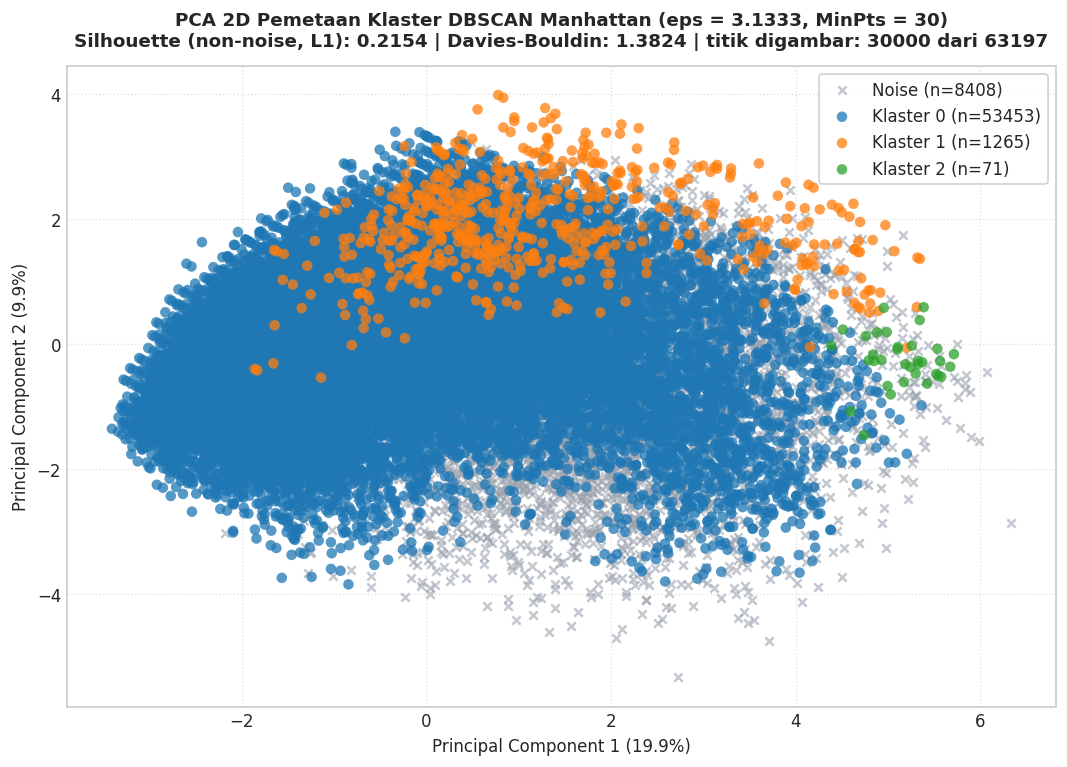

In [ ]:
# visualisasi PCA 2D pemetaan klaster
pca = PCA(n_components=2, random_state=RANDOM_STATE)
X_pca = pca.fit_transform(X_sample)

# gambar hanya PLOT_N titik acak supaya ringan; hitungan n di legenda tetap dari SEMUA data
if len(X_sample) > PLOT_N:
    idx_plot = np.sort(np.random.RandomState(RANDOM_STATE).choice(len(X_sample), size=PLOT_N, replace=False))
else:
    idx_plot = np.arange(len(X_sample))
Xp, lp = X_pca[idx_plot], labels[idx_plot]

plt.figure(figsize=(9, 6.5))
n_cl = model_dbscan.n_clusters_
palette = sns.color_palette("tab10", max(n_cl, 1))

m_noise = lp == -1
plt.scatter(Xp[m_noise, 0], Xp[m_noise, 1], c='#9CA3AF', marker='x', s=25, alpha=0.6,
            label=f'Noise (n={(labels == -1).sum()})')
for k in range(n_cl):
    mk = lp == k
    plt.scatter(Xp[mk, 0], Xp[mk, 1], color=palette[k % len(palette)], s=40, alpha=0.75, edgecolors='none',
                label=f'Klaster {k} (n={(labels == k).sum()})')

plt.title(f'PCA 2D Pemetaan Klaster DBSCAN Manhattan (eps = {EPS_FINAL}, MinPts = {MIN_PTS})\n'
          f'Silhouette (non-noise, L1): {sil_score:.4f} | Davies-Bouldin: {db_score:.4f} | titik digambar: {len(idx_plot)} dari {len(X_sample)}',
          fontsize=11, fontweight='bold', pad=12)
plt.xlabel(f'Principal Component 1 ({pca.explained_variance_ratio_[0] * 100:.1f}%)')
plt.ylabel(f'Principal Component 2 ({pca.explained_variance_ratio_[1] * 100:.1f}%)')
plt.grid(True, linestyle=':', alpha=0.6)
plt.legend(frameon=True, facecolor='white', framealpha=0.9, loc='best')
plt.tight_layout()

cluster_path = os.path.join(OUTPUT_DIR, "cluster_dbscan_manhattan.png")
plt.savefig(cluster_path, dpi=300)
print(f"[SIMPAN] Grafik pemetaan klaster disimpan ke: '{cluster_path}'")
plt.show()


In [ ]:
# fitur paling berpengaruh di PC1 & PC2
loadings = pd.DataFrame(pca.components_.T, index=df_features.columns, columns=['PC1', 'PC2'])
print("Fitur paling berpengaruh di PC1:")
print(loadings['PC1'].abs().sort_values(ascending=False).head(6).round(3))
print("\nFitur paling berpengaruh di PC2:")
print(loadings['PC2'].abs().sort_values(ascending=False).head(6).round(3))

Fitur paling berpengaruh di PC1:
GenHlth                 0.441
DiffWalk                0.408
PhysHlth                0.398
HighBP                  0.295
HeartDiseaseorAttack    0.264
PhysActivity            0.241
Name: PC1, dtype: float64

Fitur paling berpengaruh di PC2:
Age                     0.524
MentHlth                0.417
HighBP                  0.327
HeartDiseaseorAttack    0.308
HighChol                0.286
PhysHlth                0.256
Name: PC2, dtype: float64


In [ ]:
# klaster vs label diabetes (pembanding)
label_vs = pd.crosstab(df_result['Cluster_DBSCAN'], df_result[LABEL])
label_vs.columns = ['Tidak Diabetes (0)' if c == 0 else 'Diabetes (1)' for c in label_vs.columns]
label_vs['Total'] = label_vs.sum(axis=1)
if 'Diabetes (1)' in label_vs.columns:
    label_vs['Diabetes (%)'] = (label_vs['Diabetes (1)'] / label_vs['Total'] * 100).round(2)
print(f"Proporsi diabetes seluruh sampel = {(y_sample == 1).mean() * 100:.2f}%")
print(label_vs.to_string())

if model_dbscan.n_clusters_ >= 2:
    ari = adjusted_rand_score(y_sample.values[mask], labels[mask])
    print(f"\nARI klaster vs label (non-noise): {ari:.4f}")
diab_noise = int(((labels == -1) & (y_sample.values == 1)).sum())
print(f"Diabetes di noise: {diab_noise} dari {int((y_sample == 1).sum())}")

Proporsi diabetes seluruh sampel = 52.71%
                Tidak Diabetes (0)  Diabetes (1)  Total  Diabetes (%)
Cluster_DBSCAN                                                       
-1                            2607          5801   8408         68.99
 0                           26887         26566  53453         49.70
 1                             381           884   1265         69.88
 2                              10            61     71         85.92

ARI klaster vs label (non-noise): 0.0002
Diabetes di noise: 5801 dari 33312


In [ ]:
# cell 14 : bukti pendukung - jarak satu perbedaan pada fitur biner
# Setelah standardisasi, satu perbedaan pada fitur biner bernilai 1/sigma (juga untuk jarak L1).
# Kalau nilainya > eps, dua titik yang beda di fitur itu tidak mungkin bertetangga.
gap_rows = []
for col, sigma in zip(df_features.columns, scaler.scale_):
    if df_features[col].nunique() == 2:
        gap_rows.append({
            'Fitur': col,
            'Proporsi nilai 1': round(df_features[col].mean(), 3),
            'Sigma': round(sigma, 4),
            'Jarak 1 perbedaan': round(1 / sigma, 3),
            f'Melebihi eps ({EPS_FINAL})': (1 / sigma) > EPS_FINAL
        })

gap_df = pd.DataFrame(gap_rows).sort_values('Jarak 1 perbedaan', ascending=False)
print("Jarak Manhattan untuk satu perbedaan pada fitur biner:")
print(gap_df.to_string(index=False))

bukti_path = os.path.join(OUTPUT_DIR, "bukti_jarak_fitur_biner_manhattan.xlsx")
gap_df.to_excel(bukti_path, index=False)
print(f"[SIMPAN] Disimpan ke: '{bukti_path}'")

Jarak Manhattan untuk satu perbedaan pada fitur biner:
               Fitur  Proporsi nilai 1  Sigma  Jarak 1 perbedaan  Melebihi eps (3.1333)
              Stroke             0.069 0.2541              3.936                   True
HeartDiseaseorAttack             0.162 0.3684              2.715                  False
             Veggies             0.769 0.4214              2.373                  False
            DiffWalk             0.281 0.4493              2.226                  False
        PhysActivity             0.675 0.4685              2.135                  False
              Fruits             0.589 0.4919              2.033                  False
              HighBP             0.586 0.4925              2.031                  False
            HighChol             0.543 0.4981              2.008                  False
                 Sex             0.456 0.4981              2.008                  False
              Smoker             0.491 0.4999              2.000 

In [ ]:
# ===== ARI & NMI vs label Diabetes_binary =====
from sklearn.metrics import adjusted_rand_score, normalized_mutual_info_score

ALGO_NAME, METRIK_NAME = 'DBSCAN', 'Manhattan'

y_true = y_sample.values if 'y_sample' in globals() else y_label.values
lab = np.asarray(labels)
mk = lab != -1                                    # K-Means: semua True (tidak ada noise)

hasil_ext = pd.DataFrame([{
    'Algoritma': ALGO_NAME, 'Metrik': METRIK_NAME,
    'ARI (non-noise)':   round(adjusted_rand_score(y_true[mk], lab[mk]), 4),
    'NMI (non-noise)':   round(normalized_mutual_info_score(y_true[mk], lab[mk]), 4),
    'ARI (semua titik)': round(adjusted_rand_score(y_true, lab), 4),   # noise = 1 label (-1)
    'NMI (semua titik)': round(normalized_mutual_info_score(y_true, lab), 4),
}])
print(hasil_ext.to_string(index=False))

out = globals().get('OUTPUT_DIR', '.')
hasil_ext.to_excel(os.path.join(out, f'ari_nmi_{ALGO_NAME.lower()}_{METRIK_NAME.lower()}.xlsx'), index=False)

Algoritma    Metrik  ARI (non-noise)  NMI (non-noise)  ARI (semua titik)  NMI (semua titik)
   DBSCAN Manhattan           0.0002           0.0056              0.001             0.0174
